# 03 Explaining A1 (LFCC-GMM)
A1 scores every 10 ms frame as log p(frame | bona fide GMM) − log p(frame | spoof GMM) and averages. So we can see which frames drive the decision.

In [1]:
import json
from pathlib import Path
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from audio_df.data.manifests import load_manifest
from audio_df.helpers.audio import load_audio
from audio_df.helpers.eval_audio import trimmed_manifest
from audio_df.helpers.research import stats, visualization as viz
from audio_df.helpers.research.lfcc_gmm import decompose, frame_llr
from audio_df.helpers.research.runs import eer_pct as eer
from audio_df.modules.detector import GMMDetector

SR, HOP = 16000, 160
a1 = GMMDetector.load("../artifacts/a1/20261020-134519-735144")
run = Path("../runs/E-20261020-153158-819171-a1")

/Users/zuttome/LocalDocs/Learning/College/NUS/MTech-AIS/PS/GC2/SystemCode/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 Results (trimmed ASVspoof 2019, raw ITW)

In [2]:
dev_eer = json.loads((run / "metrics_eval.json").read_text())["dev_eer"]
pd.Series({"dev": dev_eer} | {p.stem[8:]: json.loads(p.read_text())["eer"] for p in run.glob("metrics_*.json")},
          name="EER %").mul(100).round(2)

dev                 12.35
eval_resample_8k    35.47
itw                 56.98
eval                21.05
eval_noise_10db     41.20
eval_opus_16k       25.56
eval_clean10k       21.80
eval_mp3_32k        42.54
Name: EER %, dtype: float64

EER is very high, performance very bad for evaulation on other datasets. model is overfitting on certain features, which is silence leading (confirm below). 

## 2 Which frames decide?
200 bona fide + 200 spoof dev clips. Raw audio, frames split into speech vs silence.

In [3]:
dev = load_manifest("../data/manifests/dev.csv", "..")
sub = dev.groupby("label").sample(200, random_state=0)
trim = trimmed_manifest(dev, "../data/cache", "dev").set_index("utt_id").loc[sub.utt_id]
d = decompose(a1, sub)
d["trimmed audio"] = [a1.score_file(p) for p in trim.path]
d.groupby("label").mean().round(2)

Trim audio dev: cache hit (24,844 clips)


,all frames,speech only,silence only,silence %,trimmed audio
label,,,,,
bonafide,1.33,0.97,1.78,46.22,0.97
spoof,-2.99,-1.59,-6.41,30.91,-1.64


In [4]:
pd.Series({c: eer(d[c], d.label) for c in ["all frames", "speech only", "silence only", "trimmed audio"]}, name="EER %")

all frames        3.5
speech only      12.0
silence only      6.5
trimmed audio    10.5
Name: EER %, dtype: float64

Silence frames are the strongest evidence: spoof silence scores -6.4 vs bona fide +1.8, and silence frames alone get 6.5% EER vs 12% for speech frames. Bona fide clips also have more silence (46% vs 31%), so the raw average gets an extra push. Remove the silence (trimmed audio) and A1 goes from 3.5% to 10.5% on this sample.

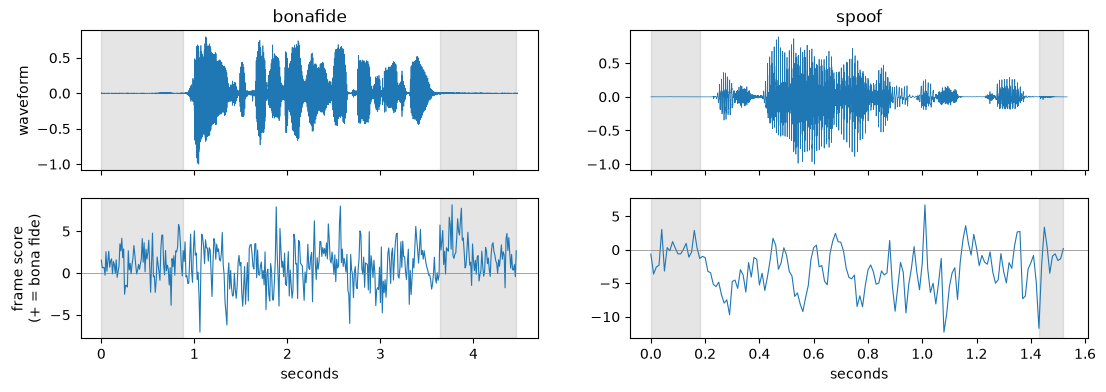

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 4), sharex="col")
for col, lab in enumerate(["bonafide", "spoof"]):
    x, llr, sp = frame_llr(a1, sub[sub.label == lab].path.iloc[0])
    t = np.arange(len(llr)) * HOP / SR
    axes[0, col].plot(np.arange(len(x)) / SR, x, lw=0.5)
    axes[0, col].set_title(lab)
    axes[1, col].plot(t, llr, lw=0.8)
    axes[1, col].axhline(0, color="grey", lw=0.5)
    axes[1, col].set_xlabel("seconds")
    for ax in axes[:, col]:
        ax.fill_between(t, 0, 1, where=~sp, transform=ax.get_xaxis_transform(), color="grey", alpha=0.2)
axes[0, 0].set_ylabel("waveform")
axes[1, 0].set_ylabel("frame score\n(+ = bona fide)")
plt.show()

Grey = silence. A1's clip score is the mean of the bottom line.

## 3 What's left after trimming
Mean log power spectrum of the trimmed clips, and spoof − bona fide effect size per frequency.

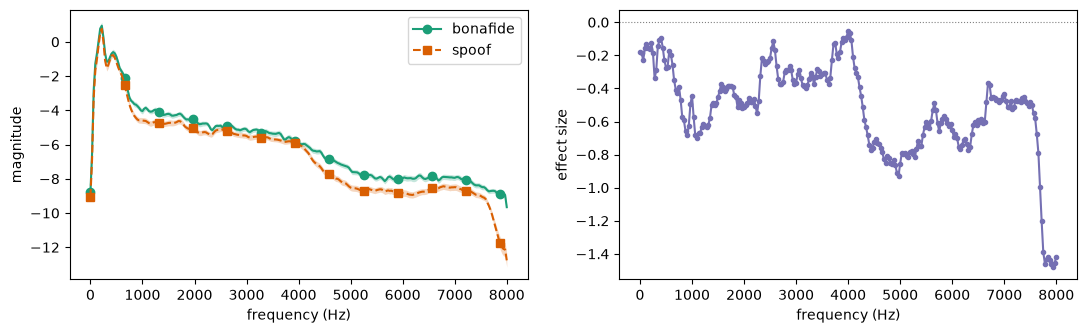

In [6]:
def spectrum(path):
    return np.log(np.abs(librosa.stft(load_audio(path, SR), n_fft=512)) ** 2 + 1e-10).mean(axis=1)

spec = {lab: np.stack([spectrum(p) for p in trim.path[sub.label.to_numpy() == lab]]) for lab in ["bonafide", "spoof"]}
freqs = librosa.fft_frequencies(sr=SR, n_fft=512)
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.5))
viz.plot_mean_spectrum_with_ci(spec, freqs, ax=a)
viz.plot_effect_size_per_bin(stats.per_bin_effect_size(spec["spoof"], spec["bonafide"]), freqs, ax=b)
plt.show()

Spoof speech has less energy at every frequency, most at 4–5 kHz and above 7.5 kHz (d ≈ -1.4 near 8 kHz). That high band is what A1 still uses after trimming.

## 4 Per attack (full trimmed eval)

In [7]:
ev = pd.read_csv(run / "scores/eval.csv")
bona = ev[ev.label == "bonafide"]
pd.Series({a: eer(pd.concat([bona, g]).score, pd.concat([bona, g]).label)
           for a, g in ev[ev.label == "spoof"].groupby("attack_id")}, name="EER %").sort_values()

A09     0.35
A08     1.32
A11     1.34
A17     2.68
A14     4.36
A15     5.98
A19    12.01
A18    22.59
A13    27.11
A07    28.96
A16    33.17
A10    37.08
A12    37.39
Name: EER %, dtype: float64

A1 is good on some attacks (A08, A09, A11 < 1.5%) and near chance on others (A10, A12, A16 > 33%). A16 is the same system as training attack A04, so even a seen attack is missed once silence is gone.

## 5 In-the-Wild
Same split into speech vs silence frames, 200 clips per class.

In [8]:
itw = load_manifest("../data/manifests/itw.csv", "..").groupby("label").sample(200, random_state=0)
di = decompose(a1, itw)
print(pd.Series({c: eer(di[c], di.label) for c in ["all frames", "speech only", "silence only"]}, name="EER %"))
di.groupby("label").mean().round(2)

all frames      57.5
speech only     64.0
silence only    56.5
Name: EER %, dtype: float64


,all frames,speech only,silence only,silence %
label,,,,
bonafide,0.47,0.47,0.28,15.03
spoof,0.45,0.86,-1.55,15.26


No silence cue in ITW (both classes ~15% silence), and on speech frames ITW spoofs look more bona fide than real ones (0.86 vs 0.47), so A1 is worse than chance. What A1 learned from 2019 speech doesn't transfer.

## 6 What in the LFCC frame the GMM uses
Each 10 ms frame is 60 numbers: 20 static coefficients (the spectrum's shape in that frame), 20 deltas and 20
delta-deltas (how that shape changes across neighbouring frames). The GMMs have diagonal covariances, so scoring
them on a subset of dimensions is exactly the GMM restricted to those dimensions, with no retraining.

Set `A1_ARTIFACT` to the model to test. The default is the one stored on this machine (trained on raw audio).
Clips are trimmed so leading silence cannot help: 400 bona fide + 40 per attack from eval.

In [9]:
from audio_df.helpers.eval_audio import trim_silence
from audio_df.helpers.research.lfcc_gmm import BAND_CENTRES as centres
from audio_df.helpers.research.lfcc_gmm import lfcc_from, log_bands, restrict

A1_ARTIFACT = "../artifacts/a1/20261020-134519-735144"
gmm = GMMDetector.load(A1_ARTIFACT)

PARTS = {"all 60": np.arange(60), "static only": np.arange(20), "deltas only": np.arange(20, 60)}
parts = {k: (restrict(gmm.bonafide, d), restrict(gmm.spoof, d), d) for k, d in PARTS.items()}

def frame_scores(feat, part="all 60"):
    bona, spoof, dims = parts[part]
    return bona.score_log_likelihood(feat[:, dims]) - spoof.score_log_likelihood(feat[:, dims])

x = trim_silence(load_audio(load_manifest("../data/manifests/eval.csv", "..").path.iloc[0], SR))
assert np.allclose(lfcc_from(log_bands(x)), gmm.features(x), atol=1e-4)  # same features as the module

In [10]:
from audio_df.helpers.research.lfcc_gmm import freeze

full_eval = load_manifest("../data/manifests/eval.csv", "..")
pick = pd.concat([full_eval[full_eval.label == "bonafide"].sample(400, random_state=0),
                  full_eval[full_eval.label == "spoof"].groupby("attack_id").sample(40, random_state=0)])
rows = []
for r in pick.itertuples():
    bands = log_bands(trim_silence(load_audio(r.path, SR)))
    feat = lfcc_from(bands)
    rows.append({"label": r.label, "attack_id": r.attack_id,
                 **{p: frame_scores(feat, p).mean() for p in PARTS},
                 "freeze 0-4 kHz": frame_scores(lfcc_from(freeze(bands, centres < 4000))).mean(),
                 "freeze 4-8 kHz": frame_scores(lfcc_from(freeze(bands, centres >= 4000))).mean()})
abl = pd.DataFrame(rows)

def attack_table(cols):
    bona = abl[abl.label == "bonafide"]
    t = pd.DataFrame({c: {a: eer(pd.concat([bona, g])[c], pd.concat([bona, g]).label)
                          for a, g in abl[abl.label == "spoof"].groupby("attack_id")} for c in cols})
    t.loc["pooled"] = [eer(abl[c], abl.label) for c in cols]
    return t

### Table 1: which part of the frame detects spoof (EER %)

In [11]:
attack_table(list(PARTS))

,all 60,static only,deltas only
A07,28.00,22.25,47.50
A08,2.50,10.00,0.00
A09,0.00,0.38,0.00
A10,37.50,35.00,47.50
A11,0.12,14.50,0.00
A12,32.50,29.50,57.50
A13,27.50,28.00,52.50
A14,5.00,27.50,0.12
A15,5.25,20.00,2.88
A16,27.00,25.00,47.50


The pooled row hides the result. On A08, A09, A11, A14 and A15 the deltas alone are near 0% EER, as good as or
better than all 60 dimensions, while the static coefficients alone are much worse (A11: 14.5%, A14: 27.5%).
These generators get the spectrum shape roughly right but move between frames differently from real
speech, and that is what the GMM detects. On A07, A10, A12, A13, A16 and A18 the deltas alone are at or past
chance (47–58%): those spoofs change from frame to frame like real speech, so this cue cannot catch them
and even points the wrong way. LFCC is therefore strong on some generators and blind to others, which is why it
needs a second, different view (D2's WavLM branch) rather than standing alone.

### Table 2: which frequency range matters (EER %)
Each column holds one half of the 20 linear bands constant over time, then recomputes the LFCC.

In [12]:
attack_table(["all 60", "freeze 0-4 kHz", "freeze 4-8 kHz"])

,all 60,freeze 0-4 kHz,freeze 4-8 kHz
A07,28.00,37.50,17.62
A08,2.50,37.38,17.38
A09,0.00,7.50,2.50
A10,37.50,40.00,35.50
A11,0.12,10.00,15.00
A12,32.50,40.00,49.38
A13,27.50,42.50,40.25
A14,5.00,32.50,35.00
A15,5.25,28.12,42.25
A16,27.00,44.75,42.12


Freezing either half costs about the same overall, but for different attacks: the high band matters most for
A12, A15 and A19, the low band for A07, A08 and A17. So there is no single important band. The GMM uses how the
whole spectrum moves, and where that difference sits depends on the generator.

### Example
Same speaker, bona fide next to A14. Top: log energy of the 20 linear bands. Bottom: the GMM's frame score from
the static part and from the delta part (15-frame moving average; legend = clip mean).

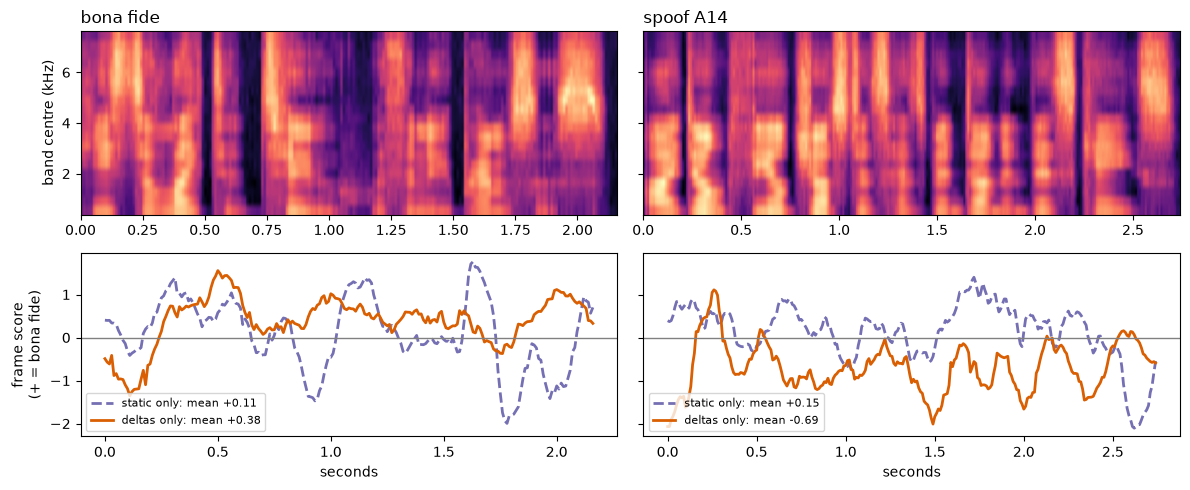

In [13]:
spk = next(s for s, g in full_eval.groupby("speaker_id") if {"-", "A14"} <= set(g.attack_id))
same = full_eval[full_eval.speaker_id == spk]
clips = [g.loc[(g.duration_s - 3).abs().idxmin()] for g in (same[same.attack_id == a] for a in ["-", "A14"])]

fig, axes = plt.subplots(2, 2, figsize=(12, 5), sharey="row")
for col, row in enumerate(clips):
    bands = log_bands(trim_silence(load_audio(row.path, SR)))
    feat, t = lfcc_from(bands), np.arange(len(bands)) * HOP / SR
    axes[0, col].imshow(bands.T, origin="lower", aspect="auto", cmap="magma",
                        extent=[0, t[-1], centres[0] / 1000, centres[-1] / 1000])
    axes[0, col].set_title("bona fide" if row.label == "bonafide" else f"spoof {row.attack_id}", loc="left")
    for part, color, style in [("static only", "#7570b3", "--"), ("deltas only", "#d95f02", "-")]:
        s = frame_scores(feat, part)
        axes[1, col].plot(t, pd.Series(s).rolling(15, center=True, min_periods=1).mean(), style, color=color,
                          linewidth=2, label=f"{part}: mean {s.mean():+.2f}")
    axes[1, col].axhline(0, color="grey", linewidth=1)
    axes[1, col].legend(fontsize=8, loc="lower left")
    axes[1, col].set_xlabel("seconds")
axes[0, 0].set_ylabel("band centre (kHz)")
axes[1, 0].set_ylabel("frame score\n(+ = bona fide)")
plt.tight_layout()
plt.show()

On the bona fide clip both parts lean positive. On A14 the static part still calls it bona fide, while the delta
part is negative through most of the clip: the spectrum shape looks real, the movement between frames does not.